# Evaluación Práctica 2: Modelado Predictivo de Ingresos Recurrentes (MRR)
## SaaSFlow — Predicción de `mrr_proximo_trimestre`

**Autores:**
- Cristóbal Soto Vidal - cristobal.soto2301@alumnos.ubiobio.cl
- Martín Romero Álvarez - martin.romero2301@alumnos.ubiobio.cl
- Benjamín Paredes Aguayo - benjamin.paredes2301@alumnos.ubiobio.cl
- Darío Silva Pedreros - dario.silva2301@alumnos.ubiobio.cl

**Asignatura:** Inteligencia Artificial (620454)  
**Fecha:** Octubre 2026

**Objetivo:** construir un modelo de Regresión Lineal que permita a la dirección comercial de SaaSFlow anticipar el nivel de MRR del próximo trimestre por cliente, para priorizar acciones de Customer Success según el riesgo y el potencial de ingreso de cada cliente.

**Estructura del notebook:**
- Fase 1: Diagnóstico y calidad de datos (EDA inicial)
- Fase 2: Limpieza y transformación (preprocesamiento + feature engineering)
- Fase 3: Construcción del modelo
- Fase 4: Evaluación e interpretación de métricas

## Cumplimiento de la rúbrica (guía de lectura)

| Criterio de la rúbrica | Dónde se cumple en este notebook |
|---|---|
| Fase 1: nulos, tipos inconsistentes, sesgos y atípicos | Fase 1: porcentaje de nulos, tipos de dato, boxplots, regla IQR y *skewness* |
| Imputación justificada por variable | Fase 2: mediana (`promedio_sesiones_mes`) y moda (`tickets_soporte`, `satisfaccion_nps`) dentro del Pipeline |
| `antiguedad_dias` sin fuga de datos | Fase 2: `AntiguedadDiasTransformer` aprende la fecha de referencia solo en train |
| Codificación y escalado | Fase 2: ordinal (`tamano_empresa`), One-Hot con `drop="first"` (`sector_empresa`), mapeo numérico (contrato, pago) y `StandardScaler` |
| División entrenamiento/prueba y modelo | Fase 3: `train_test_split` antes de todo `fit`; Pipeline con `LinearRegression` |
| R² y MAE solo sobre el conjunto de prueba | Fase 4: métricas sobre `X_test` / `y_test` |
| Interpretación financiera | Fase 4: R² y MAE en dólares, impacto en Customer Success y en flujo de caja |


---
# Fase 1: Diagnóstico y Calidad de Datos (EDA Inicial)

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

pd.set_option("display.max_columns", None)

## Carga del dataset

In [2]:
# Carga del set de datos real de clientes B2B de SaaSFlow
data = pd.read_csv("clientes_mrr_dataset.csv")
data.head()

,id_cliente,fecha_registro,sector_empresa,tamano_empresa,tickets_soporte,promedio_sesiones_mes,satisfaccion_nps,duracion_contrato,gasto_mkt_asociado,pago_puntual,mrr_proximo_trimestre
0,CLI-0001,2025-09-14 00:24:49.009633632,Finanzas,Mediana,3.0,34.350838,7.0,Mensual,3932.341944,Si,706.16
1,CLI-0002,2024-02-12 19:17:24.874829152,Tecnologia,Mediana,NaN,28.685569,8.0,Mensual,2547.833298,No,555.95
2,CLI-0003,2021-02-03 13:56:48.713623787,Tecnologia,Pequeña,5.0,50.027033,7.0,2 Años,3203.232664,Si,755.53
3,CLI-0004,2021-08-19 03:21:50.803693456,Educacion,Pequeña,0.0,NaN,9.0,Anual,603.209270,No,364.94
4,CLI-0005,2021-09-26 05:21:16.482549416,Educacion,Grande,3.0,NaN,8.0,Anual,864.788600,Si,1611.93


## Inspección general

In [3]:
# Dimensiones del dataset: filas x columnas
data.shape

(30000, 11)

In [4]:
# Tipos de dato por variable
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_cliente             30000 non-null  str    
 1   fecha_registro         30000 non-null  str    
 2   sector_empresa         30000 non-null  str    
 3   tamano_empresa         30000 non-null  str    
 4   tickets_soporte        27536 non-null  float64
 5   promedio_sesiones_mes  28455 non-null  float64
 6   satisfaccion_nps       26403 non-null  float64
 7   duracion_contrato      30000 non-null  str    
 8   gasto_mkt_asociado     30000 non-null  float64
 9   pago_puntual           30000 non-null  str    
 10  mrr_proximo_trimestre  30000 non-null  float64
dtypes: float64(5), str(6)
memory usage: 2.5 MB


**Nota:** el enunciado (`620454-E2.pdf`) describe la metadata esperada de 11 variables. El dataset real coincide en cantidad y nombres de columnas, con dos diferencias menores que no afectan el análisis: (i) el enunciado indica identificadores `CLI-0001` a `CLI-2000` (≈ 2.000 clientes), pero el dataset trae 30.000 registros (`CLI-0001` a `CLI-30000`); (ii) los sectores vienen sin tilde (`Tecnologia`, `Educacion`) en lugar de `Tecnología` y `Educación`. Se confirma además la ausencia de registros duplicados en `id_cliente`, por lo que no se requiere una etapa de deduplicación.

In [5]:
# Confirmación de unicidad del identificador de cliente
data["id_cliente"].duplicated().sum()

np.int64(0)

## Porcentaje de valores nulos por variable

In [6]:
# Porcentaje de nulos por columna, ordenado de mayor a menor
porcentaje_nulos = (data.isnull().mean() * 100).sort_values(ascending=False)
porcentaje_nulos = porcentaje_nulos[porcentaje_nulos > 0]
porcentaje_nulos.round(2)

satisfaccion_nps         11.99
tickets_soporte           8.21
promedio_sesiones_mes     5.15
dtype: float64

Solo tres variables numéricas presentan valores nulos: `satisfaccion_nps` (~12%), `tickets_soporte` (~8%) y `promedio_sesiones_mes` (~5%). Esto coincide con lo anticipado en el enunciado, que ya sugiere estrategias de imputación específicas para estas tres columnas.

## Identificación de inconsistencias de tipo de dato

In [7]:
# fecha_registro llega como texto (str) en vez de fecha
print("Tipo actual de fecha_registro:", data["fecha_registro"].dtype)
data["fecha_registro"].head()

Tipo actual de fecha_registro: str


0    2025-09-14 00:24:49.009633632
1    2024-02-12 19:17:24.874829152
2    2021-02-03 13:56:48.713623787
3    2021-08-19 03:21:50.803693456
4    2021-09-26 05:21:16.482549416
Name: fecha_registro, dtype: str

In [8]:
# Variables categóricas aún no codificadas (quedan como texto/object)
categoricas = ["sector_empresa", "tamano_empresa", "duracion_contrato", "pago_puntual"]
for col in categoricas:
    print(f"{col}: {sorted(data[col].unique())}")

sector_empresa: ['Educacion', 'Finanzas', 'Retail', 'Salud', 'Tecnologia']
tamano_empresa: ['Grande', 'Mediana', 'Pequeña']
duracion_contrato: ['2 Años', 'Anual', 'Mensual']
pago_puntual: ['No', 'Si']


Se confirman dos inconsistencias esperadas:
- `fecha_registro` está almacenada como texto y debe transformarse en una variable numérica (`antiguedad_dias`).
- Las cuatro variables categóricas (`sector_empresa`, `tamano_empresa`, `duracion_contrato`, `pago_puntual`) no están codificadas numéricamente; un modelo de Regresión Lineal no puede procesarlas directamente como texto.

## Detección de outliers (valores atípicos) — Regla IQR

> Los diagnósticos de outliers y de asimetría (*skew*) de esta fase se calculan sobre el dataset completo y son **solo descriptivos**: no alimentan ninguna transformación del pipeline. Todo estadístico que sí se usa para transformar datos (medianas, modas, medias, desviaciones estándar, fecha de referencia) se aprende únicamente en `X_train`.

In [9]:
def diagnostico_outliers_iqr(df: pd.DataFrame, columna: str) -> dict:
    """
    Diagnostica valores atípicos de una columna numérica usando la regla del
    Rango Intercuartílico (IQR = Q3 - Q1).

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame que contiene la columna a analizar.
    columna : str
        Nombre de la columna numérica a diagnosticar.

    Retorno
    -------
    dict con el límite inferior, límite superior, cantidad y porcentaje
    de registros atípicos detectados.
    """
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipicos = df[(df[columna] < limite_inferior) | (df[columna] > limite_superior)]

    return {
        "columna": columna,
        "limite_inferior": round(limite_inferior, 2),
        "limite_superior": round(limite_superior, 2),
        "n_atipicos": len(atipicos),
        "pct_atipicos": round(len(atipicos) / len(df) * 100, 2),
    }


variables_numericas = [
    "tickets_soporte",
    "promedio_sesiones_mes",
    "satisfaccion_nps",
    "gasto_mkt_asociado",
    "mrr_proximo_trimestre",
]

resumen_outliers = pd.DataFrame(
    [diagnostico_outliers_iqr(data, col) for col in variables_numericas]
)
resumen_outliers

,columna,limite_inferior,limite_superior,n_atipicos,pct_atipicos
0,tickets_soporte,-1.00,7.00,328,1.09
1,promedio_sesiones_mes,-55.96,141.50,1367,4.56
2,satisfaccion_nps,-2.00,14.00,0,0.00
3,gasto_mkt_asociado,-2352.19,7468.38,0,0.00
4,mrr_proximo_trimestre,-197.60,1553.28,607,2.02


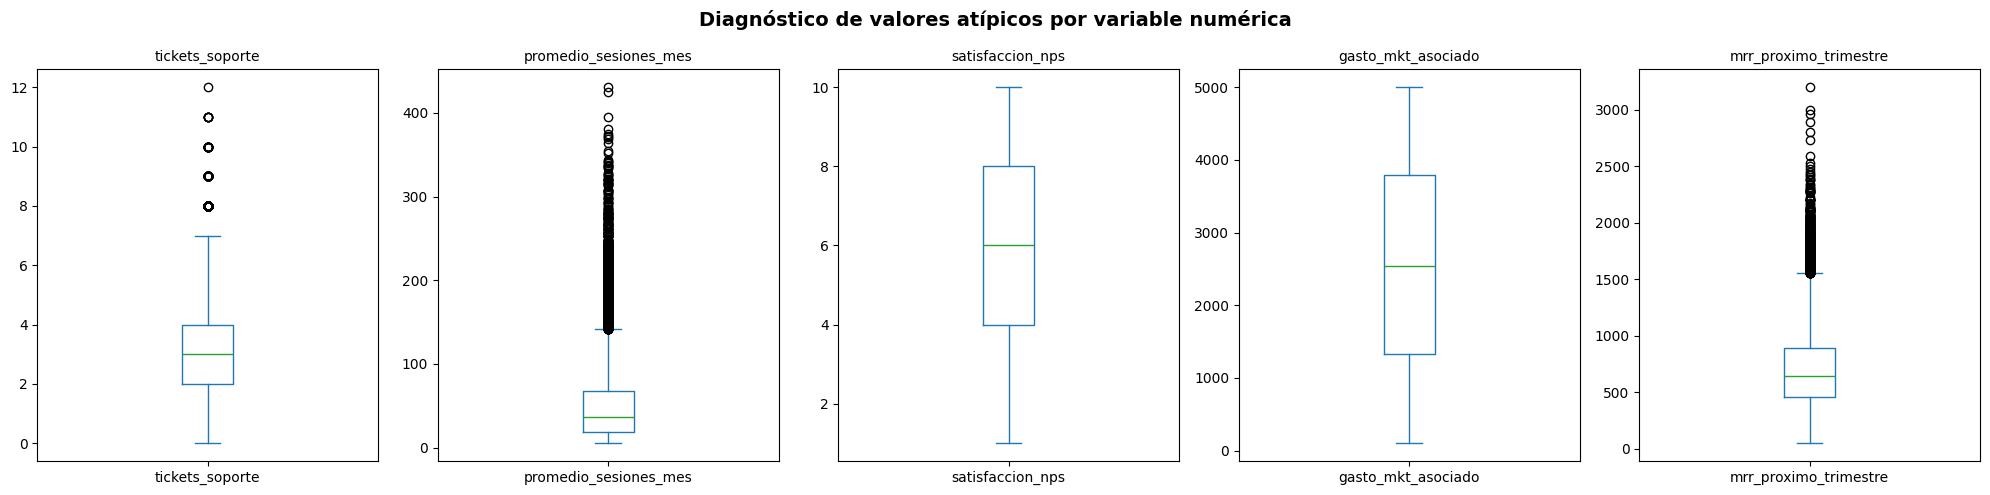

In [10]:
# Boxplots de las variables numéricas para inspección visual de atípicos
fig, axes = plt.subplots(1, len(variables_numericas), figsize=(20, 5))
for ax, col in zip(axes, variables_numericas):
    data[col].plot(kind="box", ax=ax)
    ax.set_title(col, fontsize=10)

plt.suptitle("Diagnóstico de valores atípicos por variable numérica", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

`promedio_sesiones_mes` y `mrr_proximo_trimestre` son las variables con mayor proporción de atípicos (~4.6% y ~2% respectivamente), mientras que `satisfaccion_nps` y `gasto_mkt_asociado` no presentan valores fuera de los límites IQR. Dado que estos atípicos son consistentes con comportamientos reales de clientes B2B (clientes muy intensivos o de muy bajo uso, y clientes de alto/bajo ticket) y no lucen como errores de captura, se opta por **conservarlos**: no se eliminan ni se recortan (*capping*), ya que son observaciones legítimas de la cartera y excluirlas sesgaría sistemáticamente el análisis en contra de segmentos reales de clientes.

**Escalado y atípicos:** una Regresión Lineal con intercepto es **invariante a reescalados afines** de sus variables predictoras. Usar `StandardScaler` (media/desviación estándar) o `RobustScaler` (mediana/rango intercuartílico) no cambia las predicciones ni el R²/MAE del modelo, porque ambos son transformaciones lineales que el modelo compensa ajustando sus coeficientes. La única diferencia entre ambos escaladores es la **unidad en la que quedan expresados los coeficientes** (desviaciones estándar vs. rangos intercuartílicos), no la capacidad del modelo para lidiar con outliers. Se usa `StandardScaler` por ser el estándar más interpretable (coeficiente = cambio en el target por 1 desviación estándar de la variable), y en la Fase 4 se desescalan los coeficientes a dólares por unidad real para una lectura de negocio directa.

## Asimetría (skewness) de las variables numéricas

In [11]:
# Asimetría (skewness) de todas las variables numéricas: diagnóstico descriptivo
sesgo = data[variables_numericas].skew().round(2).sort_values(ascending=False)
print("Asimetría (skewness) por variable numérica:")
print(sesgo)

Asimetría (skewness) por variable numérica:
promedio_sesiones_mes    1.97
mrr_proximo_trimestre    1.05
tickets_soporte          0.57
gasto_mkt_asociado       0.00
satisfaccion_nps        -0.42
dtype: float64


`promedio_sesiones_mes` es la variable más asimétrica (≈ 1.97, cola larga a la derecha: pocos clientes concentran el uso intensivo) y `mrr_proximo_trimestre` tiene una asimetría moderada (≈ 1.05). `tickets_soporte` es levemente asimétrica (≈ 0.57), mientras que `gasto_mkt_asociado` (≈ 0.00) y `satisfaccion_nps` (≈ −0.42) son prácticamente simétricas. No se corrige la asimetría: la Regresión Lineal no exige normalidad en los predictores y los valores extremos son comportamiento real de la cartera (ver justificación de los atípicos más arriba).

## Distribución del target: `mrr_proximo_trimestre`

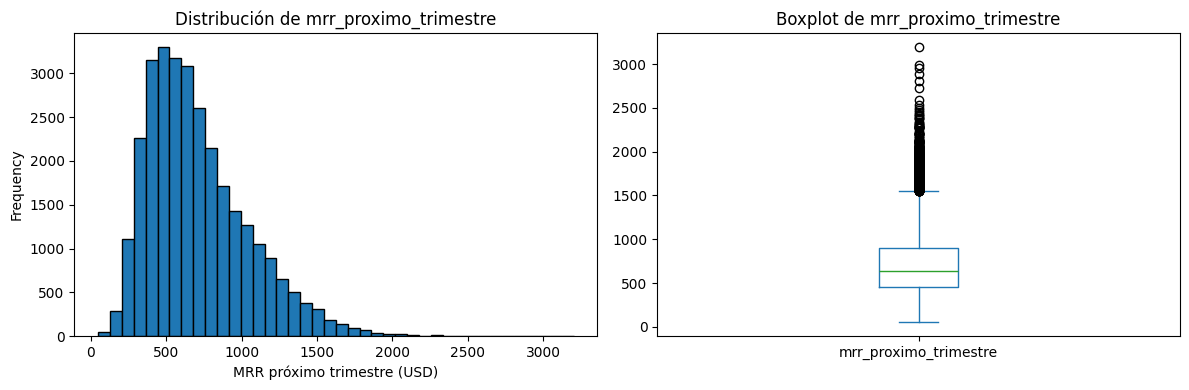

Sesgo (skewness): 1.05


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

data["mrr_proximo_trimestre"].plot(kind="hist", bins=40, ax=axes[0], edgecolor="black")
axes[0].set_title("Distribución de mrr_proximo_trimestre")
axes[0].set_xlabel("MRR próximo trimestre (USD)")

data["mrr_proximo_trimestre"].plot(kind="box", ax=axes[1])
axes[1].set_title("Boxplot de mrr_proximo_trimestre")

plt.tight_layout()
plt.show()

print("Sesgo (skewness):", round(data["mrr_proximo_trimestre"].skew(), 2))

La variable objetivo muestra un sesgo positivo moderado (asimetría a la derecha, skew ≈ 1.05): la mayoría de los clientes se concentra en niveles de MRR bajos-medios, con una cola de clientes de alto valor. Esto es coherente con la lógica de negocio de una cartera B2B, donde un grupo reducido de cuentas grandes concentra ingresos desproporcionadamente altos.

---
# Fase 2: Limpieza y Transformación (Preprocesamiento + Feature Engineering)

## Estrategia de tratamiento de nulos

- **`promedio_sesiones_mes` → mediana**: es una variable continua con posibles atípicos (clientes muy intensivos); la mediana es robusta frente a esos valores extremos y no distorsiona la escala de uso típica.
- **`tickets_soporte` → moda (valor más frecuente)**: es un conteo discreto de eventos (tickets abiertos); la mayoría de los clientes concentra pocos tickets, por lo que el valor modal representa mejor el comportamiento típico que un promedio fraccionario.
- **`satisfaccion_nps` → moda (valor más frecuente)**: es una puntuación discreta de 1 a 10; imputar con la moda evita generar puntajes NPS no enteros o poco representativos que una media podría producir.

Todas estas imputaciones se implementarán **dentro del Pipeline (`SimpleImputer`)**, ajustadas únicamente sobre el conjunto de entrenamiento, para evitar fuga de datos (data leakage).

## Ingeniería de características: `antiguedad_dias`

Se transforma `fecha_registro` (texto) en una variable numérica que mide la antigüedad del cliente en días: `antiguedad_dias = fecha_referencia − fecha_registro`.

`fecha_referencia` (el "hoy" simulado de SaaSFlow) es un estadístico aprendido, igual que la mediana de un `SimpleImputer` o la media/desviación de un `StandardScaler`: se calcula **exclusivamente sobre el conjunto de entrenamiento** (`X_train["fecha_registro"].max()`), se aprende (`fit`) solo en train y se aplica congelada (`transform`) a train y test, de modo que ningún dato del conjunto de prueba influye en la transformación. Se implementa como un transformador personalizado de Scikit-Learn (`AntiguedadDiasTransformer`, definido más abajo) que es un paso del `ColumnTransformer`, por lo que el cálculo ocurre 100% dentro del flujo `fit`/`transform` del Pipeline, sin cómputos manuales fuera de él.

En la celda siguiente solo se realiza la conversión de tipo (`texto → fecha`), una operación determinística por fila y no un estadístico agregado, por lo que no implica fuga de datos.

In [13]:
# Conversión de fecha_registro de texto a tipo fecha (operación por fila, sin fuga de datos)
data["fecha_registro"] = pd.to_datetime(data["fecha_registro"])
data["fecha_registro"].head()

0   2025-09-14 00:24:49.009633632
1   2024-02-12 19:17:24.874829152
2   2021-02-03 13:56:48.713623787
3   2021-08-19 03:21:50.803693456
4   2021-09-26 05:21:16.482549416
Name: fecha_registro, dtype: datetime64[ns]

## Mapeo binario de variables categóricas ordinales simples

`duracion_contrato` y `pago_puntual` se mapean explícitamente a valores numéricos mediante un diccionario fijo (no aprendido de los datos), por lo que también es seguro aplicarlos antes del split:
- `pago_puntual`: `No` → 0, `Si` → 1.
- `duracion_contrato`: `Mensual` → 0, `Anual` → 1, `2 Años` → 2 (jerarquía natural por duración del compromiso contractual). Se usa una escala ordinal (0/1/2), equivalente a un orden por duración del compromiso; supone que el salto Mensual → Anual vale lo mismo que Anual → 2 Años.

In [14]:
data["pago_puntual_num"] = data["pago_puntual"].map({"No": 0, "Si": 1})
data["duracion_contrato_num"] = data["duracion_contrato"].map(
    {"Mensual": 0, "Anual": 1, "2 Años": 2}
)

data[["duracion_contrato", "duracion_contrato_num", "pago_puntual", "pago_puntual_num"]].head()

,duracion_contrato,duracion_contrato_num,pago_puntual,pago_puntual_num
0,Mensual,0,Si,1
1,Mensual,0,No,0
2,2 Años,2,Si,1
3,Anual,1,No,0
4,Anual,1,Si,1


## Transformer personalizado: antigüedad de cliente sin fuga de datos

Para que `antiguedad_dias` se calcule con el mismo rigor que un `SimpleImputer` o un `StandardScaler`, se define `AntiguedadDiasTransformer`: un transformador de Scikit-Learn (`BaseEstimator` + `TransformerMixin`) que:

- En `fit(X_train)`: calcula y **guarda** `fecha_referencia_` como el máximo de `fecha_registro` observado **únicamente en el conjunto de entrenamiento**.
- En `transform(X)`: aplica esa `fecha_referencia_` ya congelada (la misma para train y para test) para calcular `antiguedad_dias = (fecha_referencia_ - fecha_registro).dias`.

Este transformador se inserta como un paso más dentro del `ColumnTransformer` (Fase 2, celda siguiente), por lo que Scikit-Learn se encarga automáticamente de llamar a `fit()` solo sobre `X_train` y a `transform()` sobre `X_train` y `X_test` — sin ningún cálculo manual fuera del Pipeline. No se usa un `FunctionTransformer` simple porque este último es *stateless* (no tiene forma nativa de "recordar" entre `fit` y `transform` un valor aprendido en entrenamiento); una clase con `TransformerMixin` sí lo permite.

In [15]:
from sklearn.base import BaseEstimator, TransformerMixin


class AntiguedadDiasTransformer(BaseEstimator, TransformerMixin):
    """
    Calcula la antigüedad en días de un cliente a partir de su fecha de registro.

    La fecha de referencia ("hoy" simulado de SaaSFlow) se aprende en fit()
    como el máximo de fecha_registro observado ÚNICAMENTE en los datos con los
    que se ajusta el transformador (en la práctica, el conjunto de
    entrenamiento, ya que este transformador vive dentro de un
    ColumnTransformer/Pipeline). Ese valor se congela en fecha_referencia_ y
    se reutiliza tal cual en transform(), igual que la mediana de un
    SimpleImputer o la media de un StandardScaler.

    Parameters
    ----------
    BaseEstimator : Clase base para estimadores en scikit-learn.
    TransformerMixin : Clase base para transformadores en scikit-learn.

    Attributes
    ----------
    fecha_referencia_ : pd.Timestamp
        Fecha máxima de fecha_registro observada en el conjunto de ajuste (fit).
    """

    def fit(self, X, y=None):
        fechas = pd.to_datetime(pd.DataFrame(X).iloc[:, 0])
        self.fecha_referencia_ = fechas.max()
        return self

    def transform(self, X):
        fechas = pd.to_datetime(pd.DataFrame(X).iloc[:, 0])
        antiguedad = (self.fecha_referencia_ - fechas).dt.days
        return antiguedad.to_numpy().reshape(-1, 1)

    def get_feature_names_out(self, input_features=None):
        return np.array(["antiguedad_dias"])

## Definición de X (features) e y (target)

Se descartan `id_cliente` (identificador, sin valor predictivo) y las columnas de texto ya reemplazadas por sus versiones numéricas mapeadas manualmente (`duracion_contrato`, `pago_puntual`).

`fecha_registro` se mantiene en `X` como fecha, sin transformar: su conversión a `antiguedad_dias` la realiza el `AntiguedadDiasTransformer` dentro del `ColumnTransformer`, de modo que `fit()` se ejecuta solo sobre `X_train` cuando se ajusta el Pipeline completo en la Fase 3.

In [16]:
X = data.drop(
    columns=[
        "id_cliente",
        "duracion_contrato",
        "pago_puntual",
        "mrr_proximo_trimestre",
    ]
)
y = data["mrr_proximo_trimestre"]

X.head()

,fecha_registro,sector_empresa,tamano_empresa,tickets_soporte,promedio_sesiones_mes,satisfaccion_nps,gasto_mkt_asociado,pago_puntual_num,duracion_contrato_num
0,2025-09-14 00:24:49.009633632,Finanzas,Mediana,3.0,34.350838,7.0,3932.341944,1,0
1,2024-02-12 19:17:24.874829152,Tecnologia,Mediana,NaN,28.685569,8.0,2547.833298,0,0
2,2021-02-03 13:56:48.713623787,Tecnologia,Pequeña,5.0,50.027033,7.0,3203.232664,1,2
3,2021-08-19 03:21:50.803693456,Educacion,Pequeña,0.0,NaN,9.0,603.209270,0,1
4,2021-09-26 05:21:16.482549416,Educacion,Grande,3.0,NaN,8.0,864.788600,1,1


## Diseño del preprocesamiento: `ColumnTransformer` + `Pipeline`

Se agrupan las variables según el tratamiento que requieren, y **todo el ajuste (imputación, escalado, codificación y cálculo de `antiguedad_dias`) se realiza únicamente sobre el conjunto de entrenamiento**, dentro de sub-pipelines encadenados en un `ColumnTransformer`:

- **Numéricas con nulos → mediana** (`promedio_sesiones_mes`): imputación por mediana + `StandardScaler`.
- **Numéricas con nulos → moda** (`tickets_soporte`, `satisfaccion_nps`): imputación por valor más frecuente + `StandardScaler`.
- **Numéricas sin nulos** (`gasto_mkt_asociado`, `duracion_contrato_num`, `pago_puntual_num`): solo `StandardScaler`.
- **`fecha_registro` → `AntiguedadDiasTransformer` + `StandardScaler`**: `fecha_referencia_` se aprende únicamente de `X_train` (dentro del `fit` del Pipeline) y se aplica congelada a train y test, igual que cualquier otro estadístico del preprocesamiento.
- **`tamano_empresa` → Ordinal Encoding**, respetando la jerarquía natural `Pequeña < Mediana < Grande`.
- **`sector_empresa` → One-Hot Encoding con `drop="first"`**, por ser una variable nominal sin orden intrínseco.

En esta sección solo se define la arquitectura del preprocesamiento: ningún imputador, escalador, encoder ni el `AntiguedadDiasTransformer` se ajusta (`fit`) aún. El ajuste ocurre en la Fase 3, después de dividir los datos.

In [17]:
num_mediana = ["promedio_sesiones_mes"]
num_moda = ["tickets_soporte", "satisfaccion_nps"]
num_sin_nulos = ["gasto_mkt_asociado", "duracion_contrato_num", "pago_puntual_num"]
col_fecha = ["fecha_registro"]
col_ordinal = ["tamano_empresa"]
col_onehot = ["sector_empresa"]

pipeline_num_mediana = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
])

pipeline_num_moda = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("escalado", StandardScaler()),
])

pipeline_num_sin_nulos = Pipeline(steps=[
    ("escalado", StandardScaler()),
])

# antiguedad_dias calculada dentro del Pipeline, con fecha_referencia_
# aprendida exclusivamente en el fit() (es decir, solo sobre X_train)
pipeline_fecha = Pipeline(steps=[
    ("antiguedad", AntiguedadDiasTransformer()),
    ("escalado", StandardScaler()),
])

pipeline_ordinal = Pipeline(steps=[
    ("encoder", OrdinalEncoder(categories=[["Pequeña", "Mediana", "Grande"]])),
])

# drop="first" evita la "trampa de las variables dummy" (dummy variable trap):
# sin esta opción, las k columnas one-hot de sector_empresa serían
# perfectamente colineales con el intercepto (su suma es siempre 1 para
# cualquier fila), lo que hace indeterminados a esos coeficientes en
# presencia de intercepto. Con drop="first" se conserva una categoría de
# referencia (la primera en orden alfabético) y el resto de los sectores se
# interpreta como diferencia respecto a ella.
pipeline_onehot = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore", drop="first")),
])

preprocesador = ColumnTransformer(transformers=[
    ("num_mediana", pipeline_num_mediana, num_mediana),
    ("num_moda", pipeline_num_moda, num_moda),
    ("num_sin_nulos", pipeline_num_sin_nulos, num_sin_nulos),
    ("fecha", pipeline_fecha, col_fecha),
    ("ordinal", pipeline_ordinal, col_ordinal),
    ("onehot", pipeline_onehot, col_onehot),
],
    remainder="drop",  # fecha_registro original y toda columna no listada NO pasan al modelo
)

preprocesador

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_mediana', ...), ('num_moda', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feat

> **Nota:** `drop="first"` solo define qué categoría de `sector_empresa` actúa como referencia implícita (absorbida por el intercepto); es una reparametrización algebraicamente equivalente del mismo espacio de hipótesis, por lo que **el R² y el MAE del modelo son exactamente los mismos** con o sin `drop="first"`. Lo que se gana es que los coeficientes de sector se interpretan sin colinealidad perfecta entre las dummies y el intercepto.

---
# Fase 3: Construcción del Modelo

## División en entrenamiento y prueba (80/20)

El `train_test_split` se realiza **antes** de ajustar cualquier imputador, escalador, encoder o el `AntiguedadDiasTransformer`. `X` contiene `fecha_registro` sin transformar, por lo que al dividir los datos aquí se garantiza que `fecha_referencia_` se calcule exclusivamente a partir de las fechas de `X_train`, sin ningún contacto con `X_test`. Se fija `random_state=42` para asegurar reproducibilidad.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Tamaño de entrenamiento:", X_train.shape)
print("Tamaño de prueba:", X_test.shape)

Tamaño de entrenamiento: (24000, 9)
Tamaño de prueba: (6000, 9)


## Pipeline sellado: preprocesamiento + Regresión Lineal

Se ensambla el `preprocesador` (definido en la Fase 2, aún sin ajustar) junto con el estimador `LinearRegression` en un único Pipeline. Al llamar a `.fit()` sobre `X_train`, todos los imputadores, el `OrdinalEncoder`, el `OneHotEncoder` y los `StandardScaler` **aprenden sus parámetros exclusivamente de los datos de entrenamiento**, garantizando cero fuga de datos hacia el conjunto de prueba.

In [19]:
modelo = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("regresion_lineal", LinearRegression()),
])

modelo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocesamiento', ...), ('regresion_lineal', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_mediana', ...), ('num_moda', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output

---
# Fase 4: Evaluación e Interpretación de Métricas

In [20]:
y_pred = modelo.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"R² (Coeficiente de Determinación): {r2:.4f}")
print(f"MAE (Error Absoluto Medio): {mae:.2f} USD")

R² (Coeficiente de Determinación): 0.9240
MAE (Error Absoluto Medio): 68.32 USD


## Interpretación en el contexto financiero de SaaSFlow

- **R² ≈ 0.92**: el modelo **explica aproximadamente el 92% de las diferencias de MRR entre clientes** a partir de las variables disponibles (uso de la plataforma, soporte, NPS, contrato, marketing y antigüedad). Es un ajuste muy sólido para un modelo lineal: significa que la mayor parte de por qué un cliente vale más o menos que otro en MRR futuro queda capturada por estas variables.
- **MAE ≈ 68 USD**: en promedio, la predicción del modelo se desvía en cerca de **68 dólares por cliente** respecto al MRR real del trimestre siguiente. Este promedio **no debe leerse como un intervalo de confianza simétrico** ("el valor real está entre X e Y"): es un promedio sobre una distribución de errores con cola larga (ver el bloque de evaluación robusta más abajo), donde la mitad de los clientes tiene un error menor a 53 USD, pero el 5% peor puede superar los 179 USD.
- **Impacto en decisiones de Customer Success**: un MAE de ~68 USD (≈9.6% del MRR promedio de 711 USD) es útil para **priorizar** — identificar qué cuentas revisar primero — pero no para cotizar con precisión el valor exacto de un cliente puntual, especialmente en cuentas pequeñas (ver el detalle por tamaño de empresa más abajo).
- **Impacto en flujo de caja**: el sesgo medio del modelo es de −0.51 USD por cliente (predicción − real, es decir, una subestimación leve y prácticamente nula), lo que significa que los errores individuales —algunos positivos, otros negativos— **se compensan al agregar la cartera completa**. Por eso la proyección del **MRR total de los 30.000 clientes es más confiable** que la predicción de un cliente específico: a nivel de cartera, el modelo sirve para planificar caja; a nivel de cliente individual, sirve para priorizar esfuerzo, no para comprometer cifras exactas.

In [21]:
print("MRR promedio observado:", round(y.mean(), 2), "USD")
print("MAE como % del MRR promedio:", round(mae / y.mean() * 100, 2), "%")

MRR promedio observado: 710.93 USD
MAE como % del MRR promedio: 9.61 %


## Evaluación robusta del modelo

Un único par (R², MAE) puede ocultar problemas importantes: ¿el modelo realmente aporta frente a no tener modelo? ¿el error se reparte parejo entre todos los clientes? ¿el resultado depende de qué partición de datos se usó? A continuación se responde cada pregunta con evidencia adicional sobre el mismo conjunto de prueba (y, para validación cruzada, sobre el conjunto de entrenamiento).

### Línea base: ¿el modelo aporta frente a "no hacer nada"?

In [22]:
from sklearn.dummy import DummyRegressor

# Línea base ingenua: predecir siempre el MRR promedio de entrenamiento
linea_base = DummyRegressor(strategy="mean")
linea_base.fit(X_train, y_train)
pred_base = linea_base.predict(X_test)

mae_base = mean_absolute_error(y_test, pred_base)
r2_base = r2_score(y_test, pred_base)
reduccion_error = (1 - mae / mae_base) * 100

print(f"Línea base (predecir el promedio) -> MAE: {mae_base:.2f} USD | R²: {r2_base:.4f}")
print(f"Regresión Lineal                 -> MAE: {mae:.2f} USD | R²: {r2:.4f}")
print(f"Reducción de error frente a la línea base: {reduccion_error:.1f}%")

Línea base (predecir el promedio) -> MAE: 266.61 USD | R²: -0.0001
Regresión Lineal                 -> MAE: 68.32 USD | R²: 0.9240
Reducción de error frente a la línea base: 74.4%


La línea base (predecir siempre el MRR promedio, sin usar ninguna variable del cliente) comete un error de ~267 USD por cliente. El modelo de Regresión Lineal reduce ese error en aproximadamente **74%**, confirmando que las variables del cliente sí aportan información real y no que el buen R² es un artefacto de una variable objetivo poco variable.

### Distribución real del error (no un intervalo de confianza)

In [23]:
error_absoluto = np.abs(y_test.values - y_pred)

percentiles = [50, 80, 90, 95]
resumen_percentiles = pd.Series(
    {f"p{p}": round(np.percentile(error_absoluto, p), 1) for p in percentiles},
    name="Error absoluto (USD)"
)
print(resumen_percentiles)

pct_dentro_mae = (error_absoluto <= mae).mean() * 100
print(f"\n% de clientes con error <= al MAE (68 USD): {pct_dentro_mae:.1f}%")

p50     53.3
p80    105.6
p90    140.6
p95    179.3
Name: Error absoluto (USD), dtype: float64

% de clientes con error <= al MAE (68 USD): 61.0%


El MAE es un promedio, no un techo: solo el **61%** de los clientes cae dentro de ±68 USD. El **80%** de los clientes tiene un error igual o menor a **106 USD**, y en el 5% de los casos más difíciles el error supera los **179 USD**. Esta distribución con cola larga es la razón por la que el MAE nunca debe presentarse como "el número real está entre X e Y dólares" — es un promedio, no un rango de confianza.

### Sesgo medio y predicciones fuera de rango

In [24]:
sesgo_medio = (y_pred - y_test.values).mean()
n_negativas = (y_pred < 0).sum()

print(f"Sesgo medio (predicción - real): {sesgo_medio:+.2f} USD por cliente")
print(f"Predicciones negativas (MRR mínimo real observado = {y.min():.0f} USD): {n_negativas}")

Sesgo medio (predicción - real): -0.51 USD por cliente
Predicciones negativas (MRR mínimo real observado = 50 USD): 7


El sesgo medio es de −0.51 USD por cliente (predicción − real): el signo negativo indica que el modelo **subestima levemente** el MRR en promedio, con una magnitud despreciable frente al MAE (68 USD). No hay una tendencia sistemática a sobreestimar ni a subestimar la cartera en su conjunto, lo cual respalda usarlo para proyectar el **MRR agregado**. Además, el modelo genera un puñado de **predicciones negativas** (7 en el conjunto de prueba; imposibles, dado que el MRR mínimo real observado es de 50 USD): una limitación esperable de un modelo lineal sin restricciones de no-negatividad, que en producción debería recortarse (`max(predicción, 0)`) antes de usarse.

### Error por tamaño de empresa: ¿el modelo falla igual en todos los segmentos?

In [25]:
analisis_segmento = X_test[["tamano_empresa"]].copy()
analisis_segmento["y_real"] = y_test.values
analisis_segmento["error_absoluto"] = error_absoluto
analisis_segmento["error_relativo_pct"] = error_absoluto / y_test.values * 100

resumen_segmento = analisis_segmento.groupby("tamano_empresa").agg(
    mae=("error_absoluto", "mean"),
    error_relativo_promedio_pct=("error_relativo_pct", "mean"),
    n_clientes=("y_real", "size"),
).reindex(["Pequeña", "Mediana", "Grande"])

resumen_segmento.round(2)

,mae,error_relativo_promedio_pct,n_clientes
tamano_empresa,,,
Pequeña,60.46,14.24,2969
Mediana,69.23,10.07,2097
Grande,91.24,7.13,934


In [26]:
mascara = y_test.values < 300
print(f"Clientes con MRR < 300 USD: {mascara.sum()} | error relativo promedio: "
      f"{(error_absoluto[mascara] / y_test.values[mascara]).mean() * 100:.1f}%")

Clientes con MRR < 300 USD: 351 | error relativo promedio: 33.9%


El error absoluto (MAE) es más alto en empresas Grandes (~91 USD) que en Pequeñas (~60 USD) — esperable, porque el MRR de las cuentas grandes es en sí mismo mayor. Pero el **error relativo** cuenta la historia opuesta: en clientes Pequeños el error equivale a ~14% de su MRR, frente a ~7% en clientes Grandes. En los 351 clientes de prueba con MRR menor a 300 USD, el error relativo promedio es de ≈34%. Esto importa para Customer Success: el modelo es proporcionalmente menos preciso justo en la base de clientes más pequeños, que además es la más numerosa (2.969 clientes Pequeños en el conjunto de prueba).

### Validación cruzada (5 folds sobre el conjunto de entrenamiento)

In [27]:
from sklearn.model_selection import KFold, cross_validate

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Una única validación cruzada que calcula ambas métricas a la vez
cv = cross_validate(
    modelo, X_train, y_train, cv=kfold,
    scoring=["r2", "neg_mean_absolute_error"],
)
r2_cv = cv["test_r2"]
mae_cv = -cv["test_neg_mean_absolute_error"]

print("R² por fold:", np.round(r2_cv, 4))
print(f"R² -> rango [{r2_cv.min():.3f}, {r2_cv.max():.3f}]")
print("\nMAE por fold (USD):", np.round(mae_cv, 2))
print(f"MAE -> rango [{mae_cv.min():.1f}, {mae_cv.max():.1f}] USD")

print(f"\nPara referencia, R² en train completo: {r2_score(y_train, modelo.predict(X_train)):.4f}")
print(f"R² en test: {r2:.4f}")

R² por fold: [0.9206 0.9143 0.9187 0.9193 0.9208]
R² -> rango [0.914, 0.921]

MAE por fold (USD): [70.21 71.27 69.42 67.22 69.86]
MAE -> rango [67.2, 71.3] USD

Para referencia, R² en train completo: 0.9188
R² en test: 0.9240


El desempeño es **estable entre folds** (R² entre 0.914 y 0.921; MAE entre 67 y 71 USD): el resultado no depende de qué partición particular de datos se usó para entrenar y evaluar. Además, el R² en entrenamiento (~0.919) es prácticamente igual al de prueba (0.924), lo que descarta sobreajuste (*overfitting*): el modelo generaliza bien, dentro de los límites de un modelo lineal.

## Extracción e interpretación de coeficientes

Primero se listan los coeficientes tal como los entrega `LinearRegression`, es decir, en las unidades internas del Pipeline: para las variables que pasaron por `StandardScaler` (uso, tickets, NPS, marketing, duración de contrato, pago puntual, antigüedad), el coeficiente representa el cambio en MRR por **una desviación estándar** de esa variable. Para `tamano_empresa` (Ordinal Encoding) y `sector_empresa` (One-Hot Encoding) **no hay escalado**, por lo que sus coeficientes ya están directamente en dólares (USD) por escalón de tamaño o por categoría de sector, respectivamente.

In [28]:
nombres_features = modelo.named_steps["preprocesamiento"].get_feature_names_out()
coeficientes = modelo.named_steps["regresion_lineal"].coef_

tabla_coeficientes = pd.DataFrame({
    "variable": nombres_features,
    "coeficiente": coeficientes,
}).sort_values(by="coeficiente", key=lambda s: s.abs(), ascending=False)

tabla_coeficientes.round(2)

,variable,coeficiente
7,ordinal__tamano_empresa,323.36
0,num_mediana__promedio_sesiones_mes,175.09
4,num_sin_nulos__duracion_contrato_num,86.18
5,num_sin_nulos__pago_puntual_num,81.19
2,num_moda__satisfaccion_nps,47.94
3,num_sin_nulos__gasto_mkt_asociado,32.97
1,num_moda__tickets_soporte,-29.43
9,onehot__sector_empresa_Retail,2.46
8,onehot__sector_empresa_Finanzas,0.67
6,fecha__antiguedad_dias,-0.28


### Coeficientes desescalados: dólares (USD) por unidad real

Para comunicarle a la dirección comercial el efecto de cada variable en su propia unidad (una sesión más, un punto más de NPS, un ticket más), se "desescalan" los coeficientes de las variables que pasaron por `StandardScaler`, dividiendo cada coeficiente estandarizado por el `scale_` (desviación estándar aprendida en `X_train`) de su propia variable:

$$\text{coeficiente}_{\text{USD}} = \frac{\text{coeficiente}_{\text{estandarizado}}}{\text{scale\_}}$$

Esto es puramente un cambio de unidades — no altera el modelo ni sus predicciones — y es matemáticamente equivalente a haber entrenado el modelo sin `StandardScaler` en esas columnas.

In [29]:
# Mapeo de cada variable escalada a su StandardScaler correspondiente dentro
# del ColumnTransformer, para recuperar su scale_ (desviación estándar en train)
grupos_escalados = {
    "num_mediana": ["promedio_sesiones_mes"],
    "num_moda": ["tickets_soporte", "satisfaccion_nps"],
    "num_sin_nulos": ["gasto_mkt_asociado", "duracion_contrato_num", "pago_puntual_num"],
    "fecha": ["antiguedad_dias"],
}

scale_por_feature = {}
for nombre_grupo, columnas in grupos_escalados.items():
    scaler = modelo.named_steps["preprocesamiento"].named_transformers_[nombre_grupo].named_steps["escalado"]
    for i, col in enumerate(columnas):
        scale_por_feature[f"{nombre_grupo}__{col}"] = scaler.scale_[i]

coeficientes_usd = []
for nombre, coef in zip(nombres_features, coeficientes):
    if nombre in scale_por_feature:
        coef_usd = coef / scale_por_feature[nombre]
        unidad = "desescalado (÷ desviación estándar de train)"
    else:
        coef_usd = coef
        unidad = "ya en USD (sin escalado: ordinal u one-hot)"
    coeficientes_usd.append({"variable": nombre, "coeficiente_usd": round(coef_usd, 3), "nota": unidad})

tabla_coeficientes_usd = pd.DataFrame(coeficientes_usd).sort_values(
    by="coeficiente_usd", key=lambda s: s.abs(), ascending=False
)
tabla_coeficientes_usd

,variable,coeficiente_usd,nota
7,ordinal__tamano_empresa,323.360,ya en USD (sin escalado: ordinal u one-hot)
5,num_sin_nulos__pago_puntual_num,204.337,desescalado (÷ desviación estándar de train)
4,num_sin_nulos__duracion_contrato_num,128.444,desescalado (÷ desviación estándar de train)
2,num_moda__satisfaccion_nps,21.825,desescalado (÷ desviación estándar de train)
1,num_moda__tickets_soporte,-17.650,desescalado (÷ desviación estándar de train)
0,num_mediana__promedio_sesiones_mes,3.990,desescalado (÷ desviación estándar de train)
9,onehot__sector_empresa_Retail,2.457,ya en USD (sin escalado: ordinal u one-hot)
8,onehot__sector_empresa_Finanzas,0.675,ya en USD (sin escalado: ordinal u one-hot)
10,onehot__sector_empresa_Salud,-0.193,ya en USD (sin escalado: ordinal u one-hot)
11,onehot__sector_empresa_Tecnologia,0.172,ya en USD (sin escalado: ordinal u one-hot)


### Comparación justa de efectos: USD por 1 desviación estándar (DE)

Los coeficientes en USD por unidad sirven para **comunicar** cada efecto en su propia escala, pero **no son comparables entre sí**: un ticket, un punto de NPS, un escalón de tamaño, una sesión y un dólar de gasto de marketing son unidades distintas. Para **ordenar** la fuerza relativa de los efectos se usa el cambio esperado en el MRR al mover cada variable en 1 desviación estándar (coeficiente × desviación estándar de la columna transformada en `X_train`). Esto aplica también a `tamano_empresa` y a las dummies de sector.

In [30]:
import scipy.sparse as sp

pre = modelo.named_steps["preprocesamiento"]
reg = modelo.named_steps["regresion_lineal"]
Xt = pre.transform(X_train)
Xt = Xt.toarray() if sp.issparse(Xt) else Xt

tabla_1de = pd.DataFrame({
    "variable": pre.get_feature_names_out(),
    "efecto_por_1_DE_usd": (reg.coef_ * Xt.std(axis=0)).round(1),
}).sort_values("efecto_por_1_DE_usd", key=abs, ascending=False)
tabla_1de

,variable,efecto_por_1_DE_usd
7,ordinal__tamano_empresa,236.2
0,num_mediana__promedio_sesiones_mes,175.1
4,num_sin_nulos__duracion_contrato_num,86.2
5,num_sin_nulos__pago_puntual_num,81.2
2,num_moda__satisfaccion_nps,47.9
3,num_sin_nulos__gasto_mkt_asociado,33.0
1,num_moda__tickets_soporte,-29.4
9,onehot__sector_empresa_Retail,0.9
6,fecha__antiguedad_dias,-0.3
8,onehot__sector_empresa_Finanzas,0.3


In [31]:
# Datos reales para contextualizar los coeficientes de sesiones y de gasto en marketing
# (desviación estándar de las sesiones observadas en X_train, sin nulos)
sesiones_train = X_train["promedio_sesiones_mes"].dropna()
print(f"Sesiones mensuales: desviación estándar ≈ {sesiones_train.std(ddof=0):.0f} | "
      f"rango p5–p95: {sesiones_train.quantile(0.05):.0f} a {sesiones_train.quantile(0.95):.0f}")

coef_gasto = tabla_coeficientes_usd.set_index("variable").loc["num_sin_nulos__gasto_mkt_asociado", "coeficiente_usd"]
print(f"gasto_mkt_asociado: {coef_gasto:+.3f} USD de MRR por cada USD de gasto")

Sesiones mensuales: desviación estándar ≈ 45 | rango p5–p95: 7 a 139
gasto_mkt_asociado: +0.023 USD de MRR por cada USD de gasto


**Lectura de negocio de los coeficientes (todo lo demás constante).** Se usa **USD por unidad** para comunicar cada efecto en su propia escala y **USD por 1 desviación estándar (DE)** para ordenar su fuerza relativa. Ordenados por efecto por 1 DE:

1. **Tamaño de empresa (`tamano_empresa`)**: **+323 USD por escalón** (Pequeña → Mediana → Grande); **+236 USD por 1 DE**. Es el efecto más fuerte.
2. **Sesiones de uso mensuales (`promedio_sesiones_mes`)**: **+4 USD por sesión**; **+175 USD por 1 DE**. El efecto por sesión es pequeño, pero el uso varía mucho entre clientes (desviación estándar ≈ 45 sesiones; rango p5–p95 de 7 a 139), por lo que es el **segundo efecto más fuerte**.
3. **Duración del contrato (`duracion_contrato_num`)**: **+128 USD por escalón** (Mensual → Anual → 2 Años); **+86 USD por 1 DE**.
4. **Puntualidad de pago (`pago_puntual_num`)**: **+204 USD** (paga a tiempo vs. no); **+81 USD por 1 DE**. El efecto por unidad es alto, pero al ser una variable binaria su efecto por 1 DE es menor que el de tamaño, sesiones y contrato.
5. **Satisfacción NPS (`satisfaccion_nps`)**: **+21.8 USD por punto**; **+48 USD por 1 DE**.
6. **Gasto de marketing asociado (`gasto_mkt_asociado`)**: **+0.023 USD de MRR por cada USD de gasto**; **+33 USD por 1 DE**.
7. **Tickets de soporte (`tickets_soporte`)**: **−17.7 USD por ticket**; **−29 USD por 1 DE**. Es el único efecto negativo relevante y, con el criterio por 1 DE, el **más débil de los efectos principales**.
8. **Antigüedad (`antiguedad_dias`) y sector (`sector_empresa`)**: efectos cercanos a 0 USD, tanto por unidad como por 1 DE: su aporte marginal es prácticamente nulo una vez controladas las demás variables.

**Importante:** estos son coeficientes de una regresión lineal, es decir, **asociaciones estadísticas controlando por las demás variables del modelo, no relaciones de causa-efecto**. Que "pago puntual" tenga un coeficiente de +204 USD no prueba que enseñarle a un cliente a pagar a tiempo vaya a aumentar su MRR en esa cifra; puede que ambas cosas (puntualidad y MRR alto) sean consecuencia de un tercer factor (por ejemplo, la salud financiera general de la empresa cliente).

## Análisis de residuos: ¿qué NO captura un modelo lineal?

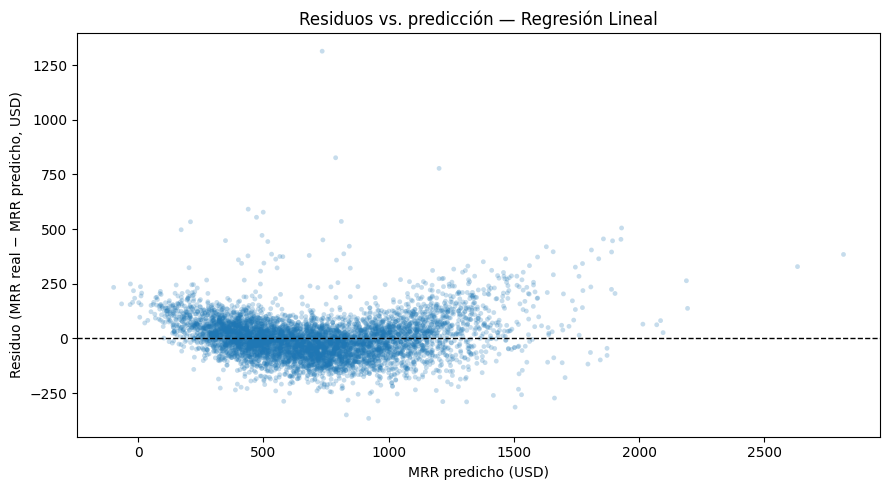

In [32]:
residuos = y_test.values - y_pred

plt.figure(figsize=(9, 5))
plt.scatter(y_pred, residuos, alpha=0.25, s=12, edgecolor="none")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("MRR predicho (USD)")
plt.ylabel("Residuo (MRR real − MRR predicho, USD)")
plt.title("Residuos vs. predicción — Regresión Lineal")
plt.tight_layout()
plt.show()

In [33]:
quintiles = pd.qcut(pd.Series(y_pred), q=5, labels=["Q1 (más bajo)", "Q2", "Q3", "Q4", "Q5 (más alto)"])
resumen_residuos = (pd.DataFrame({"residuo": residuos, "quintil_prediccion": quintiles})
                    .groupby("quintil_prediccion", observed=True)["residuo"]
                    .agg(residuo_medio="mean", desviacion="std").round(1))
print(resumen_residuos)

                    residuo_medio  desviacion
quintil_prediccion                           
Q1 (más bajo)                42.6        75.2
Q2                           -5.7        81.1
Q3                          -36.6        79.4
Q4                          -32.9        81.7
Q5 (más alto)                35.2       115.7


El gráfico de residuos muestra dos patrones que un modelo lineal ideal **no debería tener**:

1. **Forma de "U" / curvatura**: los residuos no se distribuyen aleatoriamente alrededor de cero en todo el rango de predicciones; hay una ligera curvatura sistemática. Esto sugiere que la relación real entre las variables predictoras y el MRR futuro **no es puramente lineal** — probablemente existen interacciones (p. ej., el efecto de las sesiones de uso podría ser distinto según el tamaño de la empresa) o relaciones no lineales que un modelo de Regresión Lineal simple no puede capturar por diseño. En números: el modelo subestima en los extremos (residuo medio ≈ +43 USD en el quintil más bajo de MRR predicho y ≈ +35 USD en el más alto) y sobreestima en el centro (≈ −37 USD), y la desviación de los residuos crece de ≈ 75 a ≈ 116 USD al subir el MRR predicho.
2. **Dispersión creciente (heterocedasticidad)**: la dispersión de los residuos aumenta a medida que crece el MRR predicho. Esto es consistente con lo observado en el análisis por segmento: el modelo tiene mayor error absoluto (aunque menor error relativo) en los clientes de mayor MRR.

Ninguno de estos dos patrones invalida el modelo — R² = 0.92 sigue siendo un ajuste sólido — pero sí marca el techo de lo que una Regresión Lineal puede ofrecer aquí. Explorar modelos no lineales (árboles, *gradient boosting*) o agregar términos de interacción sería el siguiente paso natural si SaaSFlow necesitara mayor precisión, especialmente en los extremos de la distribución de MRR.

## Limitaciones del modelo

- **Nivel, no cambio, de MRR**: el dataset no incluye el MRR *actual* del cliente (solo variables de comportamiento y el MRR del próximo trimestre), por lo que el modelo predice el **nivel** de MRR futuro, no su **variación** respecto al MRR presente. En consecuencia, el modelo **no detecta directamente "fugas de ingreso"** (una caída de MRR de un cliente específico); permite identificar qué clientes probablemente tendrán un MRR bajo o alto, pero no "esta cuenta va a caer un 30%" sin conocer también su MRR actual.
- **Asociación, no causalidad**: los coeficientes de la Fase 4 muestran qué variables se mueven junto con el MRR futuro **controlando por las demás**, no qué variables, si se modificaran, *causarían* un cambio en el MRR. Decisiones de negocio basadas en estos coeficientes (p. ej., migrar contratos, reducir tickets) son hipótesis razonables a probar, no garantías.
- **No linealidad residual**: como muestra el análisis de residuos, persiste una curvatura y heterocedasticidad que un modelo lineal no captura; el techo de desempeño con relaciones no lineales podría ser más alto que el R² = 0.92 observado.
- **Asimetría de las variables de entrada**: `promedio_sesiones_mes` está fuertemente sesgada a la derecha (*skewness* ≈ **1.97**), a diferencia del target (`mrr_proximo_trimestre`, *skewness* ≈ **1.05**, asimetría moderada). Esta asimetría no invalida el modelo (la regresión lineal no exige normalidad en los predictores), pero implica que un grupo relativamente pequeño de clientes con uso de plataforma muy alto pesa de forma desproporcionada en la estimación del coeficiente de esa variable.

---
## Conclusión de la Fase 4

El modelo de Regresión Lineal logra un desempeño alto y estable (R² ≈ 0.92 en test, 0.92 en validación cruzada, 0.919 en train — sin señales de sobreajuste), con una reducción de error de ~74% frente a la línea base ingenua. El error promedio (MAE ≈ 68 USD por cliente) es útil para **priorizar cuentas** y para proyectar el **MRR agregado de la cartera** (el sesgo medio es prácticamente nulo), aunque su precisión relativa es menor en los clientes de menor MRR y no debe usarse como una cifra exacta a nivel de cliente individual.

Ordenadas por su efecto por 1 desviación estándar, las variables más **asociadas** al MRR futuro son el tamaño de empresa, las sesiones de uso mensuales, la duración del contrato, la puntualidad de pago, la satisfacción NPS y el gasto de marketing asociado; los tickets de soporte son el efecto más débil de los principales (y el único negativo). Esto le da a Customer Success un mapa razonable de dónde enfocar esfuerzo, entendiendo que se trata de correlaciones controladas por el modelo y no de relaciones causales comprobadas, y que la naturaleza lineal del modelo deja algo de estructura sin capturar (ver limitaciones arriba).